In [75]:
import numpy as np
import matplotlib.pyplot as plt
def f(x, t):
    return np.tan(x)-t
def df(x):
    return 1/(np.cos(x)**2) 

def newt(x0, target, t, maxIters=10 ): 
    x = x0
    iter = 0
    errors = []
    while iter < maxIters:
        err = abs(x - target)
        errors.append(err)
        fx = f(x, t)
        dfx = df(x)
        x = x - fx / dfx
        iter += 1
    print(x)
    return errors

def secant_method(x0, x1, target, t, maxIters=10):
    errors = []
    iter = 0
    while iter < maxIters:
        err = abs(x0-target)
        errors.append(err)
        fx0 = f(x0, t)
        fx1 = f(x1, t)
        if fx1-fx0 == 0:
            for i in range(0, maxIters-iter-1):
                errors.append(0)
            break
        x_next = x1 - fx1 * (x1 - x0) / (fx1 - fx0)
        x0, x1 = x1, x_next
        iter += 1
    print(x0)
    return errors

In [76]:
err1 = newt(0.5, np.arctan(0.25), 0.25)

0.24497866312686414


In [77]:
err2 = secant_method(0.5, 1, np.arctan(0.25), 0.25)

0.24497866312686414


Text(0.5, 1.0, 'Absolute Erors ~arctan(0.25)')

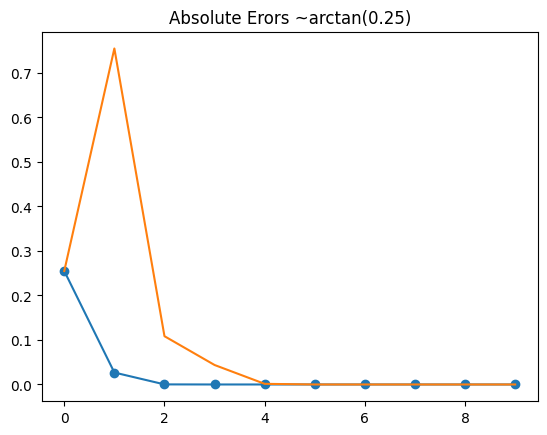

In [78]:
iterations = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
plt.plot(iterations, err1, 'o-') #orange
plt.plot(iterations, err2) #blue
plt.title('Absolute Erors ~arctan(0.25)')

In [79]:
newt_err = newt(0.5, np.arctan(0.5), 0.5)

0.46364760900080615


In [80]:
sec_err = secant_method(0.5, 1, np.arctan(0.5), 0.5)

0.4636476090008061


Text(0.5, 1.0, 'Absolute Errors ~arctan(0.5)')

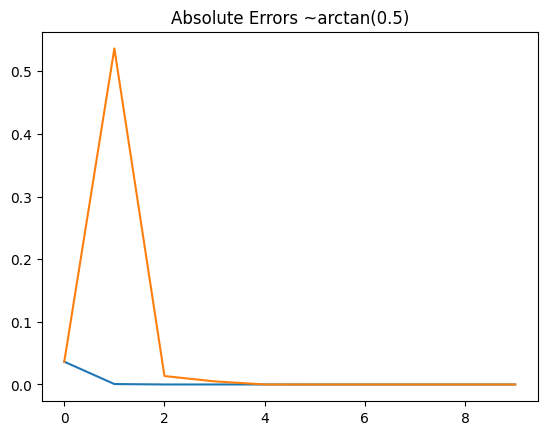

In [114]:
iterations = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
plt.plot(iterations, newt_err)
plt.plot(iterations, sec_err)
plt.title('Absolute Errors ~arctan(0.5)')

Part of the reason the graph for secant method looks a little funky is because the starting guess is worse for the secant method than newtons. Regardless though, both give the same answer, but newton's method is better because it minimizes the error in fewer iterations than the secant method

In [104]:
import numpy as np
import matplotlib.pyplot as plt
def f(x, t):
    return np.tan(x)-t
def df(x):
    return 1/(np.cos(x)**2) 

def newt2(x0, target, t, maxIters=10 ): 
    x = x0
    iter = 0
    to_plot = []
    while iter < maxIters:
        to_plot.append(20*np.log10(abs((x-target)/target)))
        fx = f(x, t)
        dfx = df(x)
        if dfx == 0:
            for i in range(0, maxIters-iter):
                to_plot.append(float('-inf'))
                iter+=1
            break
        x = x - fx / dfx
        iter += 1
    print(x)
    return to_plot

def secant_method2(x0, x1, target, t, maxIters=10):
    to_plot = []
    iter = 0
    while iter < maxIters:
        fx0 = f(x0, t)
        fx1 = f(x1, t)
        if fx1-fx0 == 0:
            for i in range(0, maxIters-iter):
                to_plot.append(float('-inf'))
            break
        to_plot.append(20*np.log10(abs((x0-target)/target)))
        x_next = x1 - fx1 * (x1 - x0) / (fx1 - fx0)
        x0, x1 = x1, x_next
        iter += 1
    print(x0)
    return to_plot

0.24497866312686414
0.24497866312686414


C:\Users\Brandon\AppData\Local\Temp\ipykernel_26780\2228369108.py:13: RuntimeWarning: divide by zero encountered in log10
  to_plot.append(20*np.log10(abs((x-target)/target)))


Text(0.5, 1.0, 'Relative Error Decibles ~arctan(0.25)')

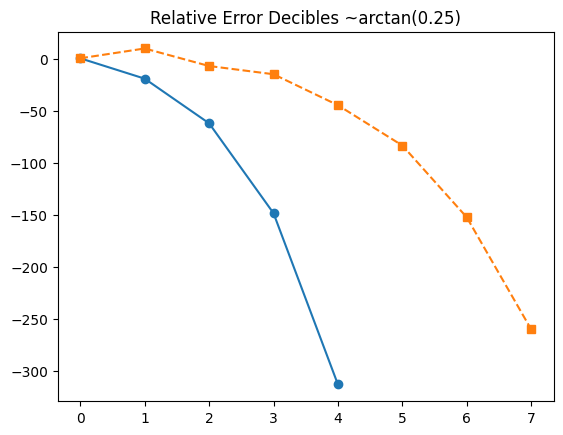

In [105]:
newt_log = newt2(0.5, np.arctan(0.25), 0.25)
to_plot = secant_method2(0.5, 1, np.arctan(0.25), 0.25)
plt.figure()
plt.plot(iterations, newt_log, 'o-', label="Newton's Method") #blue
plt.plot(iterations, to_plot, 's--', label="Secant Method") #orange
plt.title("Relative Error Decibles ~arctan(0.25)")

0.46364760900080615
0.4636476090008061


Text(0.5, 1.0, 'Relative Error Decibles ~arctan(0.5)')

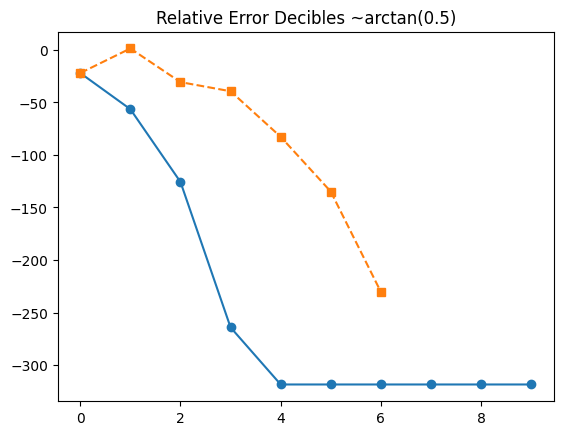

In [106]:
newt_log2 = newt2(0.5, np.arctan(0.5), 0.5)
to_plot2 = secant_method2(0.5, 1, np.arctan(0.5), 0.5)
plt.figure()
plt.plot(iterations, newt_log2, 'o-', label="Newton's Method") #blue
plt.plot(iterations, to_plot2, 's--', label="Secant Method") #orange
plt.title("Relative Error Decibles ~arctan(0.5)")

Both plots show that Newton's method converges faster than the secant method. This is likely because newtons method does not need to estimate the derivative like the secant method

In [148]:
from PIL import Image
import numpy as np
image = Image.open("HK_first_cover_art.png").convert("RGB")
img_np = np.array(image)
r, g, b = img_np[:,:,0], img_np[:,:,1], img_np[:,:,2]
gray_array = 0.3 * r + 0.6 * g + 0.1 * b
gray_array = np.clip(gray_array, 0, 255).astype(np.uint8)
gray_img = Image.fromarray(gray_array)
resized_img = gray_img.resize((256, 256))
resized_img.show()
resized_array = np.array(resized_img)


In [10]:
column1 = resized_array[:, 1]
column2 = resized_array[:, 2]
mean_X1 = np.mean(column1)
mean_Y1 = np.mean(column2)
r1 = (np.sum((column1 - mean_X1) * (column2 - mean_Y1)))/(np.sqrt(np.sum((column1 - mean_X1)**2) * np.sum((column2 - mean_Y1)**2)))
print(r1)

column3 = resized_array[:, 3]
column4 = resized_array[:, 4]
mean_X2 = np.mean(column3)
mean_Y2 = np.mean(column4)
r2 = (np.sum((column3 - mean_X2) * (column4 - mean_Y2)))/(np.sqrt(np.sum((column3 - mean_X2)**2) * np.sum((column4 - mean_Y2)**2)))
print(r2)

column5 = resized_array[:, 5]
column6 = resized_array[:, 6]
mean_X3 = np.mean(column5)
mean_Y3 = np.mean(column6)
r3 = (np.sum((column5 - mean_X3) * (column6 - mean_Y3)))/(np.sqrt(np.sum((column5 - mean_X3)**2) * np.sum((column6 - mean_Y3)**2)))
print(r3)


0.9935463469431451
0.9931591567386359
0.9900558003770987


In [11]:
compressed = resized_array[:, ::2]

In [12]:
decompressed = np.repeat(compressed, 2, axis=1)

In [13]:
new_img = Image.fromarray(decompressed)
new_img.show()

In [14]:
np.linalg.norm(resized_img) - np.linalg.norm(decompressed)

np.float64(2.996645324416022)

In [149]:
u, s, v = np.linalg.svd(resized_array, full_matrices=False)


k_values = [10, 20, 40, 80]
err_mags=[]
for i, k in enumerate(k_values):
    u_k = u[:, :k]
    s_k = s[:k]
    v_k = v[:k, :]
    A_k = np.dot(u_k, np.dot(np.diag(s_k), v_k))
    temp_img = Image.fromarray(A_k)
    temp_img.show()
    compressed_elements = (256 * k) + k + (k * 256) 
    compression_factor = 65536 / compressed_elements
    
    print(f"Compression factor: {compression_factor}")
    
   
    error_img = np.linalg.norm(resized_img) - np.linalg.norm(A_k)
    err_mags.append(error_img)

Compression factor: 12.77504873294347
Compression factor: 6.387524366471735
Compression factor: 3.1937621832358674
Compression factor: 1.5968810916179337


Text(0.5, 0, 'K Value')

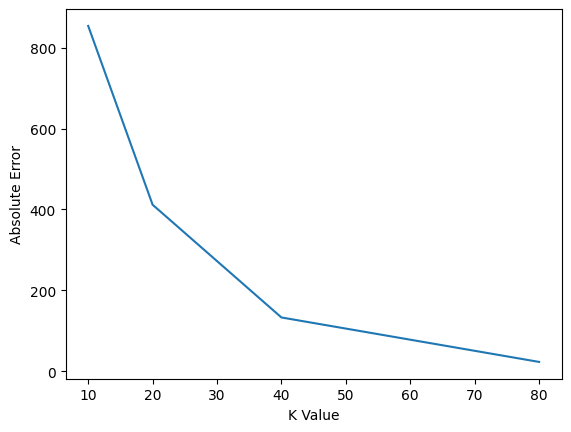

In [16]:
plt.plot(k_values, err_mags)
plt.ylabel("Absolute Error")
plt.xlabel("K Value")

**GENOMICS PROBLEM**

In [139]:
import pandas as pd
subject_labels = pd.read_csv("GSE39428_series_matrix.csv", skiprows=26, nrows=0, sep='\t')
thingy = list(subject_labels.columns)
data_labels = ['Diagnosis']
for string in thingy:
    if "ankylosing" not in string:
        if "health" in string:
            data_labels.append(0)
        else:
            data_labels.append(1)
df = pd.read_csv("GSE39428_series_matrix.csv", skiprows=58, sep='\t')
df = df.drop(df.columns[1:52], axis=1)
df = df.drop(df.index[-1])
df.loc[len(df)] = data_labels
rows, columns = df.shape

#Part b:
mapping = {"AA": 0, "AB": 1, "BB": 2, "NC": np.nan}
df = df.replace(mapping)
NC = df.isna().mean()
reliable_snps = NC[NC < 0.10].index
df_filtered = df[reliable_snps]
df_final = df_filtered[df_filtered.std(axis=1, numeric_only=True) > 0]

#Part c:
df_final.iloc[:-1, 1:] = df_final.iloc[:-1, 1:].apply(lambda x: x.fillna(x.mean()), axis=1)
df_final = pd.DataFrame(df_final.T)
df_final.columns = df_final.iloc[0]
df_final = df_final.drop(df_final.index[0])
df_final = df_final.reset_index()
y_labels = df_final['Diagnosis'].values
df_final = df_final.drop(columns=['index'])

C:\Users\Brandon\AppData\Local\Temp\ipykernel_26780\2036287220.py:19: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace(mapping)


In [140]:
df_final['Diagnosis'].value_counts()

Diagnosis
1.0    66
0.0    19
Name: count, dtype: int64

In [141]:
df_RA = df_final.loc[df_final['Diagnosis'] == 1]
RA_y = df_RA['Diagnosis'].values
df_RA = df_RA.drop(columns=['Diagnosis'])
df_healthy = df_final.loc[df_final['Diagnosis'] == 0]
healthy_y = df_healthy['Diagnosis'].values
df_healthy = df_healthy.drop(columns=['Diagnosis'])
from sklearn.model_selection import train_test_split
x_ra_train, X_ra_test, y_ra_train, Y_ra_test = train_test_split(df_RA, RA_y, test_size=0.2, random_state=2, shuffle=True)
x_healthy_train, X_healthy_test, y_healthy_train, Y_healthy_test = train_test_split(df_healthy, healthy_y, test_size=0.2, random_state=3)
train_set = pd.concat([x_ra_train ,x_healthy_train])
train_set_labels = np.concatenate([y_ra_train, y_healthy_train])
test_set = pd.concat([X_ra_test, X_healthy_test])
test_set_labels = np.concatenate([Y_ra_test, Y_healthy_test])


In [142]:
def GWAS(df_final_func, y_labels):
    #Part d:
    df_normalized = (df_final_func-df_final_func.mean())/df_final_func.std()
    SNPS = list(df_normalized.columns)
    y_labels = np.array(y_labels).astype(float)
    results = []
    for snp in SNPS:
        x = np.array(df_normalized[snp]).astype(float)
        y = y_labels
        A = np.column_stack((np.ones(len(y_labels)), x))
        beta0, beta_i = np.linalg.lstsq(A, y_labels, rcond=None)[0]
        results.append([snp, beta_i+beta0])
    results.sort(key=lambda x: x[1])

    #Part e:
    remaining_snps = list(df_normalized.columns)
    groups = {}
    snp_reps = []
    group_counter = 1


    while len(remaining_snps) > 0:
        lead_snp = remaining_snps[0]
        vec_a = df_final_func[lead_snp].values.astype(float)
        norm_a = np.linalg.norm(vec_a)
        group_members = []
        for target_snp in remaining_snps:
            vec_b = df_final_func[target_snp].values.astype(float)
            norm_b = np.linalg.norm(vec_b)
            corr = np.dot(vec_a, vec_b) / (norm_a * norm_b)
            if abs(corr) > 0.7:
                group_members.append(target_snp)
        groups[f"Group_{group_counter}"] = {
            "representative": lead_snp,
            "members": group_members,
        }
    
        remaining_snps = [snp for snp in remaining_snps if snp not in group_members]
        group_counter += 1
        snp_reps.append([lead_snp, group_counter])


    results2 = []
    for snp, group in snp_reps:
        x = ((df_final_func[snp] - df_final_func[snp].mean()) / df_final_func[snp].std()).astype(float)
        y = y_labels
        A = np.column_stack((np.ones(len(y_labels)), x))
        beta0, beta_i = np.linalg.lstsq(A, y_labels, rcond=None)[0]
        results2.append([snp, beta_i+beta0, group])
    results2.sort(key=lambda x: x[1])
    
    #Part f:
    X = df_final_func.values  
    ones_column = np.ones((X.shape[0], 1))
    A = np.hstack([ones_column, X]).astype(float)
    beta_hat, residuals, rank, s = np.linalg.lstsq(A, y_labels, rcond=None)
    predicted_y = A @ beta_hat
    top_5_indices = sorted(range(len(beta_hat)), key=lambda i: beta_hat[i], reverse=True)[:5]
    top_thingies = df_final_func.columns[top_5_indices].tolist()

    df_plot = df_final_func.copy()
    df_plot['Diagnosis'] = y_labels
    df_plot['Predicted f(x)'] = predicted_y
    import seaborn as sns
    sns.stripplot(
        data=df_plot, 
        x='Diagnosis', 
        y='Predicted f(x)', 
        hue='Diagnosis',          
        palette='Set2',        
        jitter=0.25,           
        size=6,                
        alpha=0.7,             
        legend=False           
                )
    plt.show()
    
    X_reduced = df_normalized[top_thingies].values  
    ones_column = np.ones((X_reduced.shape[0], 1))
    A_reduced = np.hstack([ones_column, X_reduced]).astype(float)
    beta_reduced, _, _, _ = np.linalg.lstsq(A_reduced, y_labels, rcond=None)
    df_plot2 = df_plot.copy()
    df_plot2['f_x_reduced'] = A_reduced @ beta_reduced
    sns.stripplot(
        data=df_plot2, 
        x='Diagnosis',               
        y='f_x_reduced', 
        hue='Diagnosis',             
        palette='Set2', 
        jitter=0.25,              
        size=6, 
        alpha=0.7, 
        legend=False
                    )
    return top_thingies, beta_reduced


In [143]:
zero_std_cols = train_set.columns[train_set.std() == 0].tolist()
print("Constant columns:", zero_std_cols)

Constant columns: ['rs28633683']


In [144]:
train_set = train_set.drop(columns=['rs28633683'])
test_set = test_set.drop(columns=['rs28633683'])
#there is onlyone subject that does not have a 1 for this gene, so it is cumbersome to try and normalize so I am dropping it

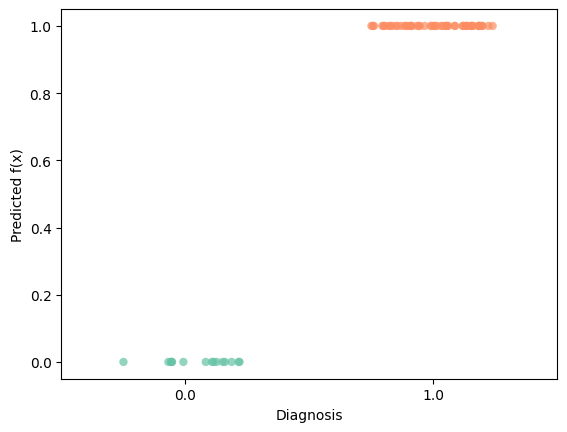

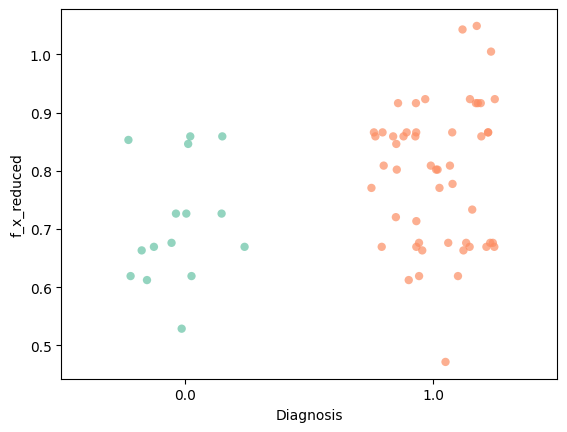

In [145]:
top_indicies, betas = GWAS(train_set, train_set_labels)

<Axes: xlabel='Diagnosis', ylabel='f_x_reduced'>

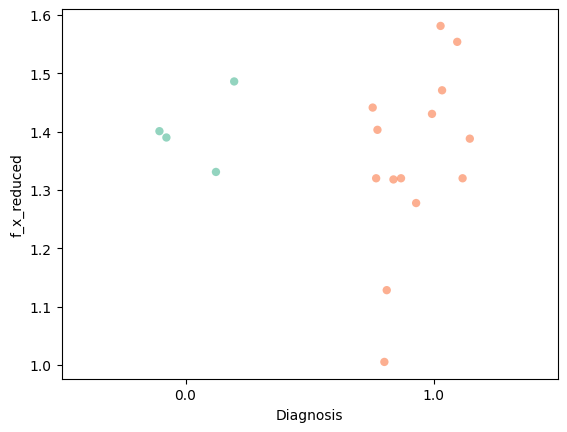

In [147]:
import seaborn as sns
X_reduced = test_set[top_indicies].values  
ones_column = np.ones((X_reduced.shape[0], 1))
A_reduced = np.hstack([ones_column, X_reduced]).astype(float)
df_plot2 = test_set.copy()
df_plot2['Diagnosis'] = test_set_labels
df_plot2['f_x_reduced'] = A_reduced @ betas
sns.stripplot(
    data=df_plot2, 
    x='Diagnosis',               
    y='f_x_reduced', 
    hue='Diagnosis',             
    palette='Set2', 
    jitter=0.25,              
    size=6, 
    alpha=0.7, 
    legend=False
                )

<Axes: xlabel='Diagnosis', ylabel='f_x_reduced'>

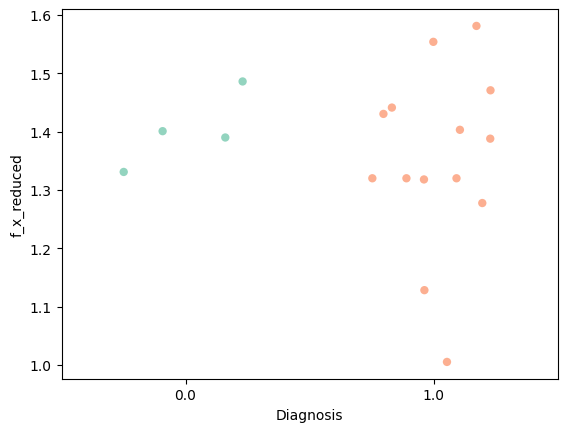

In [27]:
import seaborn as sns
X_reduced = test_set[top_indicies].values  
ones_column = np.ones((X_reduced.shape[0], 1))
A_reduced = np.hstack([ones_column, X_reduced]).astype(float)
cofs = betas
df_plot2 = test_set.copy()
df_plot2['Diagnosis'] = test_set_labels
df_plot2['f_x_reduced'] = A_reduced @ cofs
sns.stripplot(
    data=df_plot2, 
    x='Diagnosis',               
    y='f_x_reduced', 
    hue='Diagnosis',             
    palette='Set2', 
    jitter=0.25,              
    size=6, 
    alpha=0.7, 
    legend=False
                )

In [ ]:
import pandas as pd
#REDID DF WITHOUT IMPUTING
subject_labels = pd.read_csv("GSE39428_series_matrix.csv", skiprows=26, nrows=0, sep='\t')
thingy = list(subject_labels.columns)
data_labels = ['Diagnosis']
for string in thingy:
    if "ankylosing" not in string:
        if "health" in string:
            data_labels.append(0)
        else:
            data_labels.append(1)
df = pd.read_csv("GSE39428_series_matrix.csv", skiprows=58, sep='\t')
df = df.drop(df.columns[1:52], axis=1)
df = df.drop(df.index[-1])
df.loc[len(df)] = data_labels
rows, columns = df.shape
mapping = {"AA": 0, "AB": 1, "BB": 2, "NC": np.nan}
df = df.replace(mapping)
NC = df.isna().mean()
reliable_snps = NC[NC < 0.10].index
df_filtered = df[reliable_snps]
df_final = df_filtered[df_filtered.std(axis=1, numeric_only=True) > 0]
df_final = pd.DataFrame(df_final.T)
df_final.columns = df_final.iloc[0]
df_final = df_final.drop(df_final.index[0])
df_final = df_final.reset_index()
y_labels = df_final['Diagnosis'].values
df_final = df_final.drop(columns=['index'])

C:\Users\Brandon\AppData\Local\Temp\ipykernel_26780\882030728.py:19: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace(mapping)


In [108]:
df_RA = df_final.loc[df_final['Diagnosis'] == 1]
RA_y = df_RA['Diagnosis'].values
df_RA = df_RA.drop(columns=['Diagnosis'])
df_healthy = df_final.loc[df_final['Diagnosis'] == 0]
healthy_y = df_healthy['Diagnosis'].values
df_healthy = df_healthy.drop(columns=['Diagnosis'])
from sklearn.model_selection import train_test_split
x_ra_train, X_ra_test, y_ra_train, Y_ra_test = train_test_split(df_RA, RA_y, test_size=0.2, random_state=2, shuffle=True)
x_healthy_train, X_healthy_test, y_healthy_train, Y_healthy_test = train_test_split(df_healthy, healthy_y, test_size=0.2, random_state=3)
train_set = pd.concat([x_ra_train ,x_healthy_train])
train_set_labels = np.concatenate([y_ra_train, y_healthy_train])
test_set = pd.concat([X_ra_test, X_healthy_test])
test_set_labels = np.concatenate([Y_ra_test, Y_healthy_test])



Fold 1
Full model AUC: 0.6410
Five SNP model AUC: 0.3718
Selected SNPs: ['rs3825915', 'rs7165891', 'rs11247280', 'rs11574046', 'rs11657380']

Fold 2
Full model AUC: 0.6667
Five SNP model AUC: 0.8462
Selected SNPs: ['rs3825915', 'rs7165891', 'rs13210097', 'rs11168268', 'rs729906']

Fold 3
Full model AUC: 0.6410
Five SNP model AUC: 0.6667
Selected SNPs: ['rs3825915', 'rs10510123', 'rs3743191', 'rs2074478', 'rs13210097']

Fold 4
Full model AUC: 0.5128
Five SNP model AUC: 0.6154
Selected SNPs: ['rs7165891', 'rs3825915', 'rs2074478', 'rs10400863', 'rs1982906']

Fold 5
Full model AUC: 0.3673
Five SNP model AUC: 0.5816
Selected SNPs: ['rs3825915', 'rs10400863', 'rs10521184', 'rs1632346', 'rs11657380']


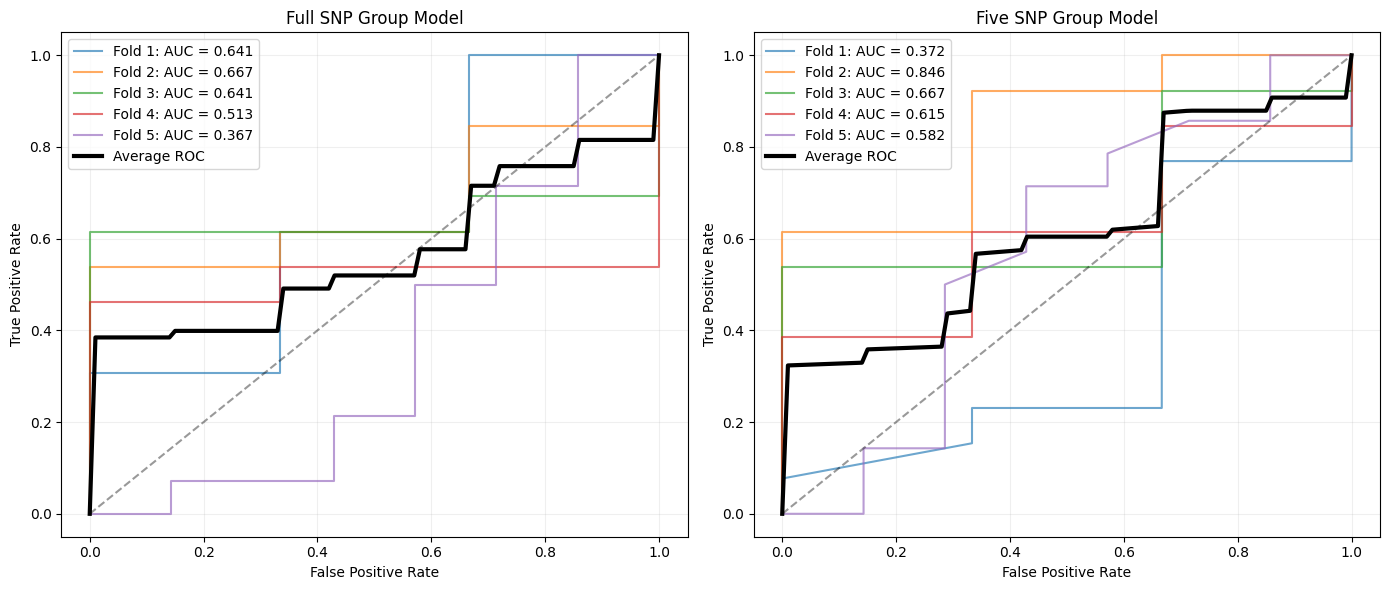


========== AUC RESULTS ==========

 Fold  Full Model AUC  Five SNP Model AUC
    1          0.6410              0.3718
    2          0.6667              0.8462
    3          0.6410              0.6667
    4          0.5128              0.6154
    5          0.3673              0.5816

Mean AUC values:
Full Model: 0.5658
Five SNP Model: 0.6163

========== MODEL COMPARISON ==========

The five-SNP-group model has the larger cross-validated AUC.

AUC differences (Five SNP - Full):
[-0.2692  0.1795  0.0256  0.1026  0.2143]

The performance difference is not consistent across all five folds.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, auc
from sklearn.impute import SimpleImputer


 #5 folds

fold1_RA = df_RA.iloc[0:13, :]
fold2_RA = df_RA.iloc[13:26, :]
fold3_RA = df_RA.iloc[26:39, :]
fold4_RA = df_RA.iloc[39:52, :]
fold5_RA = df_RA.iloc[52:, :]

fold1_healthy = df_healthy.iloc[0:3, :]
fold2_healthy = df_healthy.iloc[3:6, :]
fold3_healthy = df_healthy.iloc[6:9, :]
fold4_healthy = df_healthy.iloc[9:12, :]
fold5_healthy = df_healthy.iloc[12:, :]

folds_RA = [
    fold1_RA, fold2_RA, fold3_RA,
    fold4_RA, fold5_RA
]

folds_healthy = [
    fold1_healthy, fold2_healthy, fold3_healthy,
    fold4_healthy, fold5_healthy
]

folds = []
labels = []

for RA, healthy in zip(folds_RA, folds_healthy):

    fold = pd.concat(
        [RA, healthy],
        ignore_index=True
    )

    # RA = 1, Healthy = 0
    y = np.concatenate([
        np.ones(len(RA)),
        np.zeros(len(healthy))
    ])

    folds.append(fold)
    labels.append(y)



#New + better GWAS


def GWAS_NEW(X_train, y_train, X_test):

    #SNP to numeric
    X_train = X_train.apply(pd.to_numeric, errors='coerce')
    X_test = X_test.apply(pd.to_numeric, errors='coerce')
    y_train = np.asarray(y_train, dtype=float)
    valid_columns = X_train.columns[X_train.notna().any()]
    X_train = X_train[valid_columns]
    X_test = X_test[valid_columns]

    # Imputation
    imputer = SimpleImputer(strategy='mean')
    train_imputed = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns).astype(float)
    test_imputed = pd.DataFrame(imputer.transform(X_test), columns=X_train.columns).astype(float)

    #Normalize using training only
    train_mean = train_imputed.mean()
    train_std = train_imputed.std().replace(0, 1)
    train_normalized = (train_imputed - train_mean) / train_std
    test_normalized = (test_imputed - train_mean) / train_std

    #SNP grouping 
    remaining_snps = list(train_normalized.columns)
    snp_reps = []
    groups = {}
    group_counter = 1
    while len(remaining_snps) > 0:
        lead_snp = remaining_snps[0]
        vec_a = train_normalized[lead_snp].to_numpy(dtype=float)
        norm_a = np.linalg.norm(vec_a)
        group_members = []
        for target_snp in remaining_snps:
            vec_b = train_normalized[target_snp].to_numpy(dtype=float)
            norm_b = np.linalg.norm(vec_b)
            if norm_a == 0 or norm_b == 0:
                corr = 0
            else:
                corr = np.dot(vec_a, vec_b) / (norm_a * norm_b)
            if abs(corr) > 0.7:
                group_members.append(target_snp)
        if lead_snp not in group_members:
            group_members.append(lead_snp)

        groups[f"Group_{group_counter}"] = {
            "representative": lead_snp,
            "members": group_members
        }
        snp_reps.append(lead_snp)
        remaining_snps = [snp for snp in remaining_snps if snp not in group_members]
        group_counter += 1

    # Part 5: Full affine regression model using all SNP group representatives

    X_full_train = train_normalized[snp_reps].to_numpy(dtype=float)
    X_full_test = test_normalized[snp_reps].to_numpy(dtype=float)
    A_train = np.column_stack([np.ones(len(X_full_train)), X_full_train]).astype(float)
    A_test = np.column_stack([np.ones(len(X_full_test)), X_full_test]).astype(float)
    beta_full = np.linalg.lstsq(A_train, y_train, rcond=None)[0]
    predicted_full = A_test @ beta_full
    
    # top five SNP groups
    top_5_indices = np.argsort(np.abs(beta_full[1:]))[-5:][::-1]
    top_5_snps = [snp_reps[i] for i in top_5_indices]

    # Reduced affine
    X_reduced_train = train_normalized[top_5_snps].to_numpy(dtype=float)
    X_reduced_test = test_normalized[top_5_snps].to_numpy(dtype=float)
    A_reduced_train = np.column_stack([np.ones(len(X_reduced_train)), X_reduced_train]).astype(float)
    A_reduced_test = np.column_stack([np.ones(len(X_reduced_test)), X_reduced_test]).astype(float)
    beta_reduced = np.linalg.lstsq(A_reduced_train, y_train, rcond=None)[0]
    predicted_reduced = A_reduced_test @ beta_reduced
    return predicted_full, predicted_reduced, top_5_snps


#Five fold validation - used AI to help with plotting and reporting of results
fpr_grid = np.linspace(0, 1, 101)
all_tprs_full = []
all_tprs_reduced = []
all_aucs_full = []
all_aucs_reduced = []
selected_snps_by_fold = []
plt.figure(figsize=(14, 6))
for i in range(5):
    X_test = folds[i]
    y_test = labels[i]
    X_train = pd.concat([folds[j] for j in range(5) if j != i], ignore_index=True)
    y_train = np.concatenate([labels[j] for j in range(5) if j != i])
    predicted_full, predicted_reduced, top_5 = GWAS_NEW(X_train, y_train, X_test)
    selected_snps_by_fold.append(top_5)

    # ROC for full model
    fpr_full, tpr_full, _ = roc_curve(y_test, predicted_full)
    auc_full = auc(fpr_full, tpr_full)

    # ROC for reduced model
    fpr_reduced, tpr_reduced, _ = roc_curve(y_test, predicted_reduced)
    auc_reduced = auc(fpr_reduced, tpr_reduced)

    all_aucs_full.append(auc_full)
    all_aucs_reduced.append(auc_reduced)
    interp_full = np.interp(fpr_grid, fpr_full, tpr_full)
    interp_reduced = np.interp(fpr_grid, fpr_reduced, tpr_reduced)
    interp_full[0] = 0
    interp_reduced[0] = 0
    all_tprs_full.append(interp_full)
    all_tprs_reduced.append(interp_reduced)
    plt.subplot(1, 2, 1)
    plt.plot(fpr_full, tpr_full, label=f'Fold {i+1}: AUC = {auc_full:.3f}', alpha=0.65)
    plt.subplot(1, 2, 2)
    plt.plot(fpr_reduced, tpr_reduced, label=f'Fold {i+1}: AUC = {auc_reduced:.3f}', alpha=0.65)
    print(f"\nFold {i+1}")
    print(f"Full model AUC: {auc_full:.4f}")
    print(f"Five SNP model AUC: {auc_reduced:.4f}")
    print(f"Selected SNPs: {top_5}")


# Average ROC curves
mean_tpr_full = np.mean(all_tprs_full, axis=0)
mean_tpr_reduced = np.mean(all_tprs_reduced, axis=0)
mean_tpr_full[-1] = 1
mean_tpr_reduced[-1] = 1
mean_auc_full = np.mean(all_aucs_full)
mean_auc_reduced = np.mean(all_aucs_reduced)
plt.subplot(1, 2, 1)
plt.plot(fpr_grid, mean_tpr_full, color='black', linewidth=3, label='Average ROC')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Full SNP Group Model')
plt.legend()
plt.grid(alpha=0.2)
plt.subplot(1, 2, 2)
plt.plot(fpr_grid, mean_tpr_reduced, color='black', linewidth=3, label='Average ROC')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Five SNP Group Model')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

results_df = pd.DataFrame({
    'Fold': [1, 2, 3, 4, 5],
    'Full Model AUC': all_aucs_full,
    'Five SNP Model AUC': all_aucs_reduced
})

print("\n========== AUC RESULTS ==========\n")

print(results_df.round(4).to_string(index=False))

print("\nMean AUC values:")
print(f"Full Model: {mean_auc_full:.4f}")
print(f"Five SNP Model: {mean_auc_reduced:.4f}")

print("\n========== MODEL COMPARISON ==========\n")

if mean_auc_full > mean_auc_reduced:
    print("The full SNP group model has the larger cross-validated AUC.")

elif mean_auc_reduced > mean_auc_full:
    print("The five-SNP-group model has the larger cross-validated AUC.")

else:
    print("Both models have the same mean cross-validated AUC.")

differences = (
    np.array(all_aucs_reduced) -
    np.array(all_aucs_full)
)

print("\nAUC differences (Five SNP - Full):")
print(np.round(differences, 4))

if np.all(differences > 0):
    print("\nThe five-SNP-group model outperforms the full model in all five folds.")

elif np.all(differences < 0):
    print("\nThe full model outperforms the five-SNP-group model in all five folds.")

elif np.all(differences == 0):
    print("\nBoth models have identical AUCs in all five folds.")

else:
    print("\nThe performance difference is not consistent across all five folds.")

Using fewer features helps gaurd against model overfitting, so a model with less features would do better on unseen data.

In [ ]:
import numpy as np

def construct_and_solve_spline(x, y):
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)
    N = len(x)
    num_segments = N - 1
    num_unknowns = 4 * num_segments
    A = np.zeros((num_unknowns, num_unknowns))
    q = np.zeros(num_unknowns)
    h = np.diff(x)
    row = 0
    
    # Left Boundary: s_i(x_i) = a_i = y_i
    for i in range(num_segments):
        A[row, 4 * i] = 1.0
        q[row] = y[i]
        row += 1
        
    # Right Node Boundary: a_i + b_i*h_i + c_i*h_i^2 + d_i*h_i^3 = y_{i+1}
    for i in range(num_segments):
        A[row, 4 * i] = 1.0          # a_i
        A[row, 4 * i + 1] = h[i]       # b_i
        A[row, 4 * i + 2] = h[i]**2    # c_i
        A[row, 4 * i + 3] = h[i]**3    # d_i
        q[row] = y[i + 1]
        row += 1
        
    # b_i + 2*c_i*h_i + 3*d_i*h_i^2 - b_{i+1} = 0
    for i in range(num_segments - 1):
        A[row, 4 * i + 1] = 1.0        # b_i
        A[row, 4 * i + 2] = 2 * h[i]   # c_i
        A[row, 4 * i + 3] = 3 * h[i]**2 # d_i
        A[row, 4 * (i + 1) + 1] = -1.0 # b_{i+1}
        q[row] = 0.0
        row += 1
        
    # 2*c_i + 6*d_i*h_i - 2*c_{i+1} = 0
    for i in range(num_segments - 1):
        A[row, 4 * i + 2] = 2.0        # c_i
        A[row, 4 * i + 3] = 6 * h[i]   # d_i
        A[row, 4 * (i + 1) + 2] = -2.0 # c_{i+1}
        q[row] = 0.0
        row += 1

    # s''_1(x_1) = 2*c_1 = 0
    A[row, 2] = 2.0
    q[row] = 0.0
    row += 1
    
    # s''_{N-1}(x_N) = 2*c_{N-1} + 6*d_{N-1}*h_{N-1} = 0
    last_seg = num_segments - 1
    A[row, 4 * last_seg + 2] = 2.0
    A[row, 4 * last_seg + 3] = 6 * h[last_seg]
    q[row] = 0.0
    row += 1
    
    z = np.linalg.solve(A, q)
    coefficients_per_segment = z.reshape((num_segments, 4))
    return A, q, coefficients_per_segment


In [33]:
x = [0, 1, 2, 3, 4, 5]
y = [0, 2, 1, 3, 2, 2.5]
a, q, cofs = construct_and_solve_spline(x, y)

In [34]:
cofs

array([[ 0.        ,  3.08373206,  0.        , -1.08373206],
       [ 2.        , -0.16746411, -3.25119617,  2.41866029],
       [ 1.        ,  0.5861244 ,  4.00478469, -2.59090909],
       [ 3.        ,  0.82296651, -3.76794258,  1.94497608],
       [ 2.        , -0.87799043,  2.06698565, -0.68899522]])

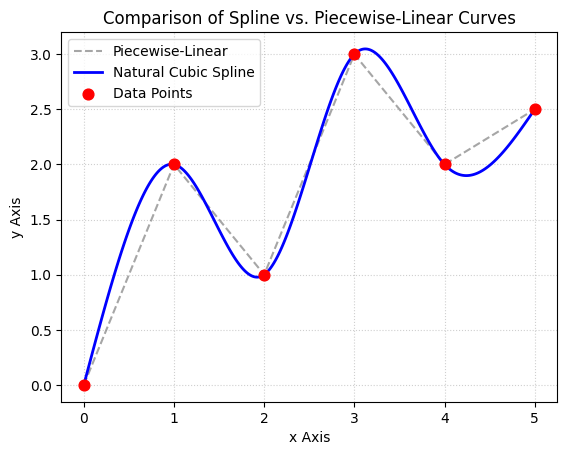

In [ ]:
plt.plot(x, y, '--', color='gray', alpha=0.7, label='Piecewise-Linear')
for i in range(len(x) - 1):
    x_dense = np.linspace(x[i], x[i+1], 100)
    dx = x_dense - [i]
    a, b, c, d = cofs[i]
    y_dense = a + b*dx + c*(dx**2) + d*(dx**3)
    label = 'Natural Cubic Spline' if i == 0 else ""
    plt.plot(x_dense, y_dense, color='blue', linewidth=2, label=label)
# 3. Plot Original Nodes
plt.scatter(x, y, color='red', s=60, zorder=5, label='Data Points')
# Adjust Layout Options
plt.title('Comparison of Spline vs. Piecewise-Linear Curves', fontsize=12)
plt.xlabel('x Axis')
plt.ylabel('y Axis')
plt.legend()
plt.show()